# Exercises on TNR — solutions
### Exercises on tensor network renormalization: write your own TRG and beat Onsager

There is a chest on [Isla de Muerta](https://pirates.fandom.com/wiki/Isla_de_Muerta) that only opens for someone
who can compute the free energy of the 2D Ising model in the thermodynamic limit, to five digits, with code they
wrote themselves. We sail there via a few islands, with a
touch of a famous pirate film series as our guide.

**The goal.** Get to know tensor network renormalization (TNR) by writing the code yourself, step by step.
On the way you will

1. derive the tensor network for the partition function of the 2D Ising model,
2. write your own TNR scheme from scratch: the [tensor renormalization group (TRG)](https://tensornetwork.org/trg/)
   of Levin and Nave, and
3. compute the free energy of a lattice of $2^{30} \approx 10^9$ spins and compare it with Onsager's
   exact solution.

**What you need.** No prior knowledge of TNR. We do assume you are comfortable with Python and numpy
(arrays, `reshape`, `transpose`, `np.linalg.svd`); there is a short refresher on `np.einsum` in
[Port Royal](#0-port-royal-before-we-set-sail).

**How it works.** The notebook guides you through every step. Each task has hints folded away underneath it,
and each stop ends with a checkpoint that tells you whether you can sail on. Stuck, or curious about something
else? Don't be afraid to ask us!

**Running the notebook.** The easiest way is in Google Colab. The notebook then runs on
Google's machines, with numpy, scipy and matplotlib already installed, so there is nothing to set up.
You are of course free to download it and run it in your favorite environment (VS Code, JupyterLab, ...).

---
© 2026 Jarid Piceu ([jarid.piceu@ugent.be](mailto:jarid.piceu@ugent.be)) and Atsushi Ueda
([atsushi.ueda@ugent.be](mailto:atsushi.ueda@ugent.be)), Ghent University.
Free to use, share and adapt under the [MIT License](https://github.com/dartsushi/TNR_tutorial/blob/main/LICENSE).
If you do, please mention or cite us.

## About these solutions

This notebook contains a complete, working solution for every stop of `Exercises on TNR.ipynb`.
The code follows [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) (v0.7) closely. The table below lists the counterpart of each function, so you
can open the package afterwards and recognize what you see.

**Contents:** [0 Port Royal](#0-port-royal-before-we-set-sail) · [1 Tortuga](#1-tortuga-building-the-ising-tensor) · [2 Shipwreck Cove](#2-shipwreck-cove-breaking-a-tensor-in-two) ·
[3 Fort Charles](#3-fort-charles-one-trg-step) · [4 The Maelstrom](#4-the-maelstrom-iterating-and-the-free-energy) · [5 Isla de Muerta](#5-isla-de-muerta-the-chest) ·
[6 The real treasure](#6-the-real-treasure-tnrkitjl) · [7 World's End](#7-worlds-end-extras)

| Stop | Exercise function | [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) counterpart |
|---|---|---|
| 1 | `ising_tensor` | `classical_ising(Trivial, β)` in `src/models/ising.jl` |
| 2 | `split_tensor` | `SVD12` in `src/utility/projectors.jl` |
| 3 | `trg_step` | `step!(::TRG, trunc)` in `src/schemes/trg.jl` |
| 4 | `trg_free_energy` | `run!` + `finalize!` + `free_energy` in `src/schemes/tnrscheme.jl`, `src/utility/finalize.jl`, `src/utility/free_energy.jl` |
| [7.5](#75-the-deep-end-central-charge-and-scaling-dimensions) | `transfer_matrix`, `scaling_dimensions`, `central_charge` | `CFTData(scheme; shape = [1, 1, 0])` in `src/utility/cft.jl` |

---
<a id="0-port-royal-before-we-set-sail" name="0-port-royal-before-we-set-sail"></a>

## 0. Port Royal: before we set sail

> **Fun fact.** [Port Royal](https://en.wikipedia.org/wiki/Port_Royal), Jamaica, was the pirate capital of the Caribbean and was called "the wickedest city on Earth", until an earthquake sank much of it into the sea in 1692.

Run the toolbox below. It defines:

| name | what it is |
|---|---|
| `beta_c` | critical inverse temperature $\beta_c = \tfrac12\ln(1+\sqrt2) \approx 0.4407$ |
| `f_exact(beta)` | Onsager's exact free energy per site |
| `lnZ_bruteforce(beta, L)` | $\ln Z$ of an $L\times L$ torus by brute-force enumeration |
| `checkpoint_island1(...)`, ... | the checkpoints |
| `open_treasure_chest(...)` | the final test |

In [47]:
# TOOLBOX
# Run this cell once. You don't need to read it, but nobody will stop you.
# Only uses numpy, scipy and matplotlib, which Colab has pre-installed.

import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad
from scipy.special import ellipk

beta_c = 0.5 * np.log(1 + np.sqrt(2))  # critical inverse temperature ≈ 0.4406867935
TREASURE_BETAS = [0.3, 0.4, beta_c, 0.5, 0.6]  # the five β's that guard the chest


# ---------- exact results (Onsager 1944, Yang 1952) ----------
def f_exact(beta):
    """Onsager's exact free energy per site of the 2D Ising model (J = 1, h = 0)."""
    k = 1 / np.sinh(2 * beta) ** 2
    integrand = lambda th: np.log(np.cosh(2 * beta) ** 2 + np.sqrt(1 + k**2 - 2 * k * np.cos(2 * th)) / k)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        val, _ = quad(integrand, 0, np.pi, epsabs=1e-13, epsrel=1e-13, limit=500)
    return -(np.log(2) / 2 + val / (2 * np.pi)) / beta


def u_exact(beta):
    """Exact internal energy per site, u = d(βf)/dβ (diverging slope at β_c)."""
    t = np.tanh(2 * beta)
    k = 2 * np.sinh(2 * beta) / np.cosh(2 * beta) ** 2
    return -(1 / t) * (1 + (2 / np.pi) * (2 * t**2 - 1) * ellipk(k**2))


def m_exact(beta):
    """Yang's spontaneous magnetization: (1 - sinh(2β)^-4)^(1/8) for β > β_c, zero otherwise."""
    beta = np.asarray(beta, dtype=float)
    return np.where(beta > beta_c, np.abs(1 - np.sinh(2 * beta) ** -4.0) ** 0.125, 0.0)


# critical exponents and the lowest scaling dimensions of the 2D Ising universality class
ISING_EXPONENTS = {"alpha": 0, "beta": 1 / 8, "gamma": 7 / 4, "delta": 15, "nu": 1, "eta": 1 / 4}
ISING_CFT = [0, 1 / 8, 1, 9 / 8, 9 / 8, 2, 2, 2, 2, 17 / 8]


# ---------- brute force and exact contraction on tiny tori ----------
def lnZ_bruteforce(beta, L, h=0.0):
    """ln Z of an L x L periodic Ising lattice (field h) by summing all 2^(L*L) configurations."""
    n = L * L
    spins = 1 - 2 * ((np.arange(2**n)[:, None] >> np.arange(n)) & 1)
    s = spins.reshape(-1, L, L)
    E = (s * np.roll(s, 1, axis=1)).sum((1, 2)) + (s * np.roll(s, 1, axis=2)).sum((1, 2))
    x = beta * E + beta * h * s.sum((1, 2))
    return x.max() + np.log(np.exp(x - x.max()).sum())


def lnZ_tensor_torus(T, L):
    """ln Z of an L x L torus built from copies of T[l, d, u, r], contracted exactly."""
    T = np.asarray(T, dtype=float)
    D = T.shape[0]
    R = T
    for _ in range(L - 1):  # a ring of L tensors -> row transfer matrix
        n = R.shape[1]
        R = np.einsum("adub,bevc->adeuvc", R, T).reshape(D, n * D, n * D, D)
    TM = np.einsum("adua->du", R)
    return np.log(np.trace(np.linalg.matrix_power(TM, L)))


# ---------- pretty printing ----------
def _ok(msg):
    print("✅ " + msg)


def _fail(msg):
    print("❌ " + msg)
    return False


def _todo(name):
    print(f"…  `{name}` still returns None. Fill it in first.")
    return False


# ---------- checkpoints ----------
def checkpoint_island1(boltzmann_weight, bond_factor, ising_tensor):
    beta = 0.4
    W, M, T = boltzmann_weight(beta), bond_factor(beta), ising_tensor(beta)
    for name, x in (("boltzmann_weight", W), ("bond_factor", M), ("ising_tensor", T)):
        if x is None:
            return _todo(name)
    W, M, T = np.asarray(W), np.asarray(M), np.asarray(T)
    s = np.array([1, -1])
    if W.shape != (2, 2) or not np.allclose(W, np.exp(beta * np.outer(s, s))):
        return _fail("boltzmann_weight is off. Remember: index 0 <-> spin +1, index 1 <-> spin -1.")
    _ok("W is correct.")
    if M.shape != (2, 2) or not np.allclose(M @ M.T, W):
        return _fail("bond_factor: M @ M.T does not reproduce W.")
    _ok("M @ M.T reproduces W.")
    if T.shape != (2, 2, 2, 2):
        return _fail(f"ising_tensor should have shape (2, 2, 2, 2), got {T.shape}.")
    for b in (0.3, beta_c, 0.6):
        Tb = np.asarray(ising_tensor(b))
        for L in (2, 3, 4):
            mine, exact = lnZ_tensor_torus(Tb, L), lnZ_bruteforce(b, L)
            if not np.isclose(mine, exact, rtol=1e-10, atol=1e-10):
                return _fail(
                    f"On a {L}x{L} torus at β = {b:.4f}: ln Z(tensor) = {mine:.10f}, "
                    f"but brute force gives {exact:.10f}."
                )
    _ok("ln Z on 2x2, 3x3 and 4x4 tori agrees with brute-force enumeration (up to 65 536 configurations).")
    print("\nYou have a tensor. Next stop: Shipwreck Cove.")
    return True


def checkpoint_island2(split_tensor):
    rng = np.random.default_rng(7)
    X = rng.standard_normal((3, 4, 5, 2))
    A, B = split_tensor(X, 100)
    if A is None or B is None:
        return _todo("split_tensor")
    A, B = np.asarray(A), np.asarray(B)
    if A.ndim != 3 or B.ndim != 3:
        return _fail(f"A and B should both have 3 legs, got shapes {A.shape} and {B.shape}.")
    if A.shape[:2] != (3, 4) or B.shape[1:] != (5, 2) or A.shape[2] != B.shape[0]:
        return _fail(f"Expected A[i, j, a] and B[a, k, l]; got shapes {A.shape} and {B.shape}.")
    if not np.allclose(np.einsum("ija,akl->ijkl", A, B), X):
        return _fail("Without truncation, A·B should reproduce T exactly.")
    _ok("Without truncation, A·B reproduces T exactly.")
    A, B = split_tensor(X, 3)
    A, B = np.asarray(A), np.asarray(B)
    if A.shape != (3, 4, 3) or B.shape != (3, 5, 2):
        return _fail(f"With chi = 3 expected shapes (3, 4, 3) and (3, 5, 2); got {A.shape} and {B.shape}.")
    s = np.linalg.svd(X.reshape(12, 10), compute_uv=False)
    err = np.linalg.norm(np.einsum("ija,akl->ijkl", A, B) - X)
    if not np.isclose(err, np.sqrt(np.sum(s[3:] ** 2))):
        return _fail("Truncated split is not optimal. Did you keep the LARGEST singular values?")
    _ok("With truncation, the error is the optimal one (Eckart–Young).")
    nA, nB = np.linalg.norm(A), np.linalg.norm(B)
    if not np.isclose(nA, nB, rtol=1e-8):
        print("(Works, but A and B have very different norms. Giving √S to both sides keeps things balanced.)")
    print("\nSplit works. Next stop: Fort Charles.")
    return True


def _test_tensor():
    # a deliberately ugly, non-symmetric tensor: it catches swapped legs
    return np.fromfunction(lambda l, d, u, r: np.cos(1 + l + 2 * d + 3 * u + 5 * r) + 0.3 * l * r + 0.1 * d, (2, 2, 2, 2))


def checkpoint_island3(trg_step):
    T = _test_tensor()
    Tn = trg_step(T, 4)
    if Tn is None:
        return _todo("trg_step")
    Tn = np.asarray(Tn)
    if Tn.ndim != 4:
        return _fail(f"The new tensor should have 4 legs, got shape {Tn.shape}.")
    two_sites = np.einsum("abcd,dcba->", T, T)
    if not np.isclose(np.einsum("abba->", Tn), two_sites):
        return _fail(
            "A 1x1 torus of the NEW tensor should equal a 2-site torus of the OLD tensor "
            f"({two_sites:.8f}), got {np.einsum('abba->', Tn):.8f}. Check which legs you glue together."
        )
    _ok("1x1 torus of T_new equals the 2-site torus of T.")
    h = np.einsum("abbc,cdda->", Tn, Tn)
    v = np.einsum("abca,dcbd->", Tn, Tn)
    if not (np.isclose(h, 26.519232143495525) and np.isclose(v, 25.181410635798148)):
        return _fail(
            "The 2x1 and 1x2 tori of the new tensor are wrong: probably the legs of T_new are in the "
            "wrong order. Output order must be (l, d, u, r) of the rotated lattice."
        )
    _ok("Leg order (l, d, u, r) of T_new is right.")
    Tb = trg_step(trg_step(np.ones((2, 2, 2, 2)) + _test_tensor(), 3), 3)
    if np.asarray(Tb).shape != (3, 3, 3, 3):
        return _fail(f"With chi = 3, the new tensor should be (3, 3, 3, 3), got {np.asarray(Tb).shape}.")
    _ok("Bond dimension is capped at χ.")
    print("\nThe hard part is behind you. Next stop: the Maelstrom.")
    return True


def checkpoint_island4(trg_free_energy):
    beta = 0.35
    f = trg_free_energy(beta, 8, 20)
    if f is None:
        return _todo("trg_free_energy")
    fe = f_exact(beta)
    rel = abs(f - fe) / abs(fe)
    print(f"   β = {beta}, χ = 8, 20 steps:  f_TRG = {f:.10f}   f_exact = {fe:.10f}   rel. error = {rel:.2e}")
    if rel > 1e-4:
        _diagnose(f, fe, beta)
        return False
    _ok("Within 1e-4 of Onsager.")
    print("\nSet course for Isla de Muerta.")
    return True


def _diagnose(f, fe, beta):
    d = (f - fe) * beta
    if abs(d + np.log(2)) < 1e-2 or abs(d - np.log(2)) < 1e-2:
        _fail("You are off by exactly ln(2)/β: a factor 2 per site too many (or too few) in your tensor/normalization.")
    elif abs(f / fe - 2) < 0.05 or abs(f / fe - 0.5) < 0.05:
        _fail("You are off by a factor 2: check the weights 1/2^k (does the initial norm get weight 1?).")
    else:
        _fail("Not accurate enough yet. Check your normalization and the sum ln Z / N = Σ_k ln(n_k) / 2^k.")


def checkpoint_field(ising_tensor_h):
    T = ising_tensor_h(0.4, 0.1)
    if T is None:
        return _todo("ising_tensor_h")
    for b, h in ((0.3, 0.0), (0.4, 0.1), (beta_c, -0.25), (0.6, 0.5)):
        Tb = np.asarray(ising_tensor_h(b, h))
        for L in (2, 3, 4):
            mine, exact = lnZ_tensor_torus(Tb, L), lnZ_bruteforce(b, L, h)
            if not np.isclose(mine, exact, rtol=1e-10, atol=1e-10):
                return _fail(f"{L}x{L} torus at β = {b:.4f}, h = {h}: ln Z(tensor) = {mine:.10f}, brute force {exact:.10f}.")
    _ok("ln Z with a magnetic field agrees with brute force on 2x2, 3x3 and 4x4 tori.")
    return True


def checkpoint_cft(trg_tensors, scaling_dimensions, central_charge, chi=16, step=8):
    Ts = trg_tensors(beta_c, chi, step)
    if Ts is None:
        return _todo("trg_tensors")
    T = Ts[step]
    D = scaling_dimensions(T, 2, 6)
    c = central_charge(T)
    if D is None:
        return _todo("scaling_dimensions")
    if c is None:
        return _todo("central_charge")
    D = np.real(np.asarray(D))
    print(f"   step {step}, χ = {chi}:  c = {c:.4f},  Δ = {np.round(D, 4)}")
    if not np.allclose(D[:3], [0, 1 / 8, 1], atol=0.02):
        return _fail("The lowest scaling dimensions should be close to 0, 1/8, 1.")
    _ok("Δ_σ ≈ 1/8 and Δ_ε ≈ 1.")
    if abs(c - 0.5) > 0.02:
        return _fail("The central charge should be close to 1/2.")
    _ok("c ≈ 1/2. You just identified the Ising CFT from a 16x16x16x16 array of numbers.")
    return True


CHEST = r"""
            __________
           /\____;;___\
          | /         /       The chest opens.
          `. ())oo() .
           |\(%()*^^()^\      Your own tensor and your own TRG agree with
          %| |-%-------|      Onsager to {digits} digits, on a billion spins.
         % \ | %  ))   |
         %  \|%________|      "Not all treasure is silver and gold, mate."
                              (see section 6)
"""


def open_treasure_chest(trg_free_energy, chi=16, n_steps=30):
    print(f"Testing your TRG at χ = {chi}, {n_steps} RG steps (a lattice of 2^{n_steps} ≈ {2**n_steps:.1e} spins)\n")
    print(f"{'β':>8} {'T = 1/β':>8} {'f_TRG':>16} {'f_exact':>16} {'rel. error':>11} {'time':>7}")
    worst, ok = 0.0, True
    for beta in TREASURE_BETAS:
        t0 = time.time()
        f = trg_free_energy(beta, chi, n_steps)
        if f is None:
            return _todo("trg_free_energy")
        dt = time.time() - t0
        fe = f_exact(beta)
        rel = abs(f - fe) / abs(fe)
        worst = max(worst, rel)
        flag = "✅" if rel < 1e-5 else "❌"
        ok &= rel < 1e-5
        tag = "  <- β_c" if np.isclose(beta, beta_c) else ""
        print(f"{beta:8.5f} {1/beta:8.4f} {f:16.12f} {fe:16.12f} {rel:11.2e} {dt:6.2f}s {flag}{tag}")
    if ok:
        print(CHEST.format(digits=int(-np.log10(worst))))
    else:
        print("\nThe chest stays shut: every β needs a relative error below 1e-5.")
        print("Is χ really 16? Do you normalize after every step?")
    return ok


print("Toolbox loaded. β_c =", beta_c)

Toolbox loaded. β_c = 0.44068679350977147


### Conventions

**The model.** Classical Ising spins $\sigma_i = \pm 1$ on a square lattice, nearest-neighbor coupling $J=1$, no external magnetic field $h=0$:

$$Z(\beta) = \sum_{\{\sigma\}} \prod_{\langle ij\rangle} e^{\beta\,\sigma_i\sigma_j},
\qquad f = -\frac{1}{\beta}\lim_{N\to\infty}\frac{\ln Z}{N}.$$

**Indices.** In code, spin $+1 \leftrightarrow$ index `0` and spin $-1 \leftrightarrow$ index `1`.

**Leg order.** Every 4-leg tensor in this notebook is stored as `T[l, d, u, r]` = **left, down, up, right**:

```text
            u (2)
            |
   l (0) ---T--- r (3)
            |
            d (1)
```

This is exactly the convention of [**TNRKit.jl**](https://github.com/QuantumKitHub/TNRKit.jl/) (there written as a map $V_l\otimes V_d \leftarrow V_u\otimes V_r$),
so what you build today plugs straight into the package. Neighbouring tensors are glued
`r` ↔ `l` (horizontally) and `u` ↔ `d` (vertically). 

Most bugs today will probably be erros with the order of the legs, so it pays to keep this picture in mind.

### A two-minute `einsum` refresher

`np.einsum` contracts tensors written in index notation. Every input gets a string of letters, one letter per
leg. The letters after `->` are the legs you keep; every letter that appears in the inputs but not in the output
is summed over.

| maths | `einsum` |
|---|---|
| matrix product $C_{ik} = \sum_j A_{ij}B_{jk}$ | `np.einsum('ij,jk->ik', A, B)` |
| trace $\sum_i A_{ii}$ | `np.einsum('ii->', A)` |
| transpose $B_{ji} = A_{ij}$ | `np.einsum('ij->ji', A)` |
| outer product $C_{ij} = a_i b_j$ | `np.einsum('i,j->ij', a, b)` |
| $v_i = \sum_{jk} T_{ijk}\,x_j\,y_k$ | `np.einsum('ijk,j,k->i', T, x, y)` |

Two things worth knowing for today:
* A letter may appear in more than two inputs, e.g. `'sl,sd,su,sr->ldur'`. It is then a single index shared
  by all of them, summed once. That comes in handy in Tortuga.
* With three or more tensors, pass `optimize=True`. Without it numpy sums over all indices in one go, which
  for a TRG step costs $\chi^8$ instead of $\chi^6$.

In [48]:
# Quick check: all of these should print True
A, B = np.random.rand(3, 4), np.random.rand(4, 5)
print(np.allclose(np.einsum("ij,jk->ik", A, B), A @ B))
print(np.isclose(np.einsum("ii->", A[:, :3]), np.trace(A[:, :3])))

# This one comes back in section 4: glue leg l to r and leg d to u of a 4-leg tensor
T = np.random.rand(2, 2, 2, 2)
print(np.isclose(np.einsum("abba->", T), sum(T[a, b, b, a] for a in range(2) for b in range(2))))

True
True
True


---
<a id="1-tortuga-building-the-ising-tensor" name="1-tortuga-building-the-ising-tensor"></a>

## 1. Tortuga: building the Ising tensor

> **Fun fact.** [Tortuga](https://en.wikipedia.org/wiki/Tortuga_%28Haiti%29) is a real island off the north coast of Haiti. In the 17th century it was the stronghold of the buccaneers.

Every voyage starts in Tortuga, recruiting a crew. Ours is a single tensor, but copied a billion times.
The job: rewrite

$$Z = \sum_{\{\sigma\}} \prod_{\langle ij\rangle} W_{\sigma_i\sigma_j}, \qquad W_{\sigma\sigma'} = e^{\beta\sigma\sigma'},$$

as a **tensor network**: one tensor $T$ on every site, contracted over the bonds,
$Z = \mathrm{tTr}\,\bigotimes_{x} T^{(x)}$.

**The recipe.** The weight $W$ lives on a *bond* and couples *two* spins. A tensor lives on a *site*.
So we cut every bond in half, and give one half to each end:

```text
   σ_i ───── W ───── σ_j      =      σ_i ── M ──(a)── Mᵀ ── σ_j          W = M Mᵀ
```

Now every site $i$ carries its spin $\sigma_i$ and **four** half-bonds (left, down, up, right).
Summing over the spin $\sigma_i$ leaves a tensor with four bond legs:

$$T_{ldur} \;=\; \sum_{\sigma=\pm1} M_{\sigma l}\,M_{\sigma d}\,M_{\sigma u}\,M_{\sigma r}.$$

### Your task
1. `boltzmann_weight(beta)`: the $2\times2$ matrix $W$.
2. `bond_factor(beta)`: any $2\times2$ matrix $M$ with $M M^{T} = W$.
3. `ising_tensor(beta)`: the site tensor `T[l, d, u, r]`.

<details><summary>Hint 1: the weight matrix</summary>

With index 0 = spin up and index 1 = spin down:
$W = \begin{pmatrix} e^{\beta} & e^{-\beta} \\ e^{-\beta} & e^{\beta}\end{pmatrix}$.
`np.outer(s, s)` with `s = np.array([1, -1])` gives you all products $\sigma\sigma'$ at once.
</details>

<details><summary>Hint 2: splitting the bond</summary>

$W$ is real symmetric, so $W = U\Lambda U^T$ and $M = U\sqrt{\Lambda}$ works (`np.linalg.eigh`).
Explicitly, the eigenvalues are $2\cosh\beta$ and $2\sinh\beta$ with eigenvectors $(1,\pm1)/\sqrt2$, giving

$M = \begin{pmatrix} \sqrt{\cosh\beta} & \sqrt{\sinh\beta} \\ \sqrt{\cosh\beta} & -\sqrt{\sinh\beta}\end{pmatrix}.$

(Any other $M' = M O$ with $O$ orthogonal is equally valid. That is a *gauge freedom* of the network.)
</details>

<details><summary>Hint 3: gluing the four halves</summary>

`np.einsum` translates the formula letter by letter:
```python
T = np.einsum('sl,sd,su,sr->ldur', M, M, M, M)
```
</details>

In [49]:
def boltzmann_weight(beta):
    """W[s, s'] = exp(beta * σ σ'), with index 0 <-> σ = +1 and index 1 <-> σ = -1."""
    s = np.array([1, -1])
    return np.exp(beta * np.outer(s, s))


def bond_factor(beta):
    """Any 2x2 matrix M with M @ M.T == W.

    W = U Λ Uᵀ with Λ = diag(2cosh β, 2sinh β) and U = [[1, 1], [1, -1]]/√2, so M = U √Λ.
    """
    c, s = np.sqrt(np.cosh(beta)), np.sqrt(np.sinh(beta))
    return np.array([[c, s], [c, -s]])


def ising_tensor(beta):
    """The Ising site tensor T[l, d, u, r] = Σ_σ M[σ,l] M[σ,d] M[σ,u] M[σ,r]."""
    M = bond_factor(beta)
    return np.einsum("sl,sd,su,sr->ldur", M, M, M, M)

**Checkpoint 1**

In [50]:
checkpoint_island1(boltzmann_weight, bond_factor, ising_tensor)

✅ W is correct.
✅ M @ M.T reproduces W.
✅ ln Z on 2x2, 3x3 and 4x4 tori agrees with brute-force enumeration (up to 65 536 configurations).

You have a tensor. Next stop: Shipwreck Cove.


True

#### A quick question: answer
With the $M$ above, index 0 of a bond carries $\sqrt{\cosh\beta}$ and index 1 carries $\pm\sqrt{\sinh\beta}$, with the sign equal to $\sigma$. Hence

$$T_{ldur} = (\sqrt{\cosh\beta})^{\#0}\,(\sqrt{\sinh\beta})^{\#1}\sum_{\sigma=\pm1}\sigma^{\,l+d+u+r}
= 2\,(\sqrt{\cosh\beta})^{4-n}(\sqrt{\sinh\beta})^{n}\;\delta_{n\ \mathrm{even}},\qquad n=l+d+u+r .$$

The sum over $\sigma$ kills every entry with an odd number of 1's: the global $\mathbb{Z}_2$ spin-flip symmetry
becomes a **local parity rule** on the tensor. This is precisely the tensor [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) builds in
`classical_ising(Trivial, β)` (as `2 * parity * bond_tensor⁴`), and `classical_ising(Z2Irrep, β)` stores only the non-zero symmetry blocks. The cell below checks that they agree **exactly**.

In [51]:
def classical_ising_tnrkit(beta):
    parity = np.fromfunction(lambda i, j, k, l: (i + j + k + l) % 2 == 0, (2, 2, 2, 2)).astype(float)
    B = np.diag([np.sqrt(np.cosh(beta)), np.sqrt(np.sinh(beta))])
    return 2 * np.einsum("ijkl,ai,bj,kc,ld->abcd", parity, B, B, B, B)


T = ising_tensor(0.4)
print("non-zero entries:", np.count_nonzero(np.abs(T) > 1e-14), "of", T.size)
print("|T_mine - T_TNRKit| =", np.linalg.norm(T - classical_ising_tnrkit(0.4)))

non-zero entries: 8 of 16
|T_mine - T_TNRKit| = 0.0


---
<a id="2-shipwreck-cove-breaking-a-tensor-in-two" name="2-shipwreck-cove-breaking-a-tensor-in-two"></a>

## 2. Shipwreck Cove: breaking a tensor in two

> **Fun fact.** In the films, [Shipwreck Cove](https://pirates.fandom.com/wiki/Shipwreck_Cove) hides Shipwreck City, a pirate fortress built from the wrecks of countless ships, and one of the few safe havens left for pirates.

TRG's basic move is to **break a 4-leg tensor into two 3-leg tensors** along a diagonal, and to throw
overboard everything but the $\chi$ most important channels in between:

```text
            k                                 k
            |                                 |
     i -----X----- l       ≈              ----B----- l
            |                            /
            j                       (a) /   ← at most χ values
                                       /
                            i -----A---
                                   |
                                   j
```

Group the legs $(i,j)$ into a row index and $(k,l)$ into a column index, take a (truncated) SVD
$X \approx U S V^\dagger$, and absorb $\sqrt{S}$ on both sides:

$$X_{ijkl} \approx \sum_{a=1}^{\chi} A_{ija}\,B_{akl},\qquad A = U\sqrt{S},\quad B=\sqrt{S}\,V^\dagger .$$

By the [Eckart–Young theorem](https://en.wikipedia.org/wiki/Low-rank_approximation) this is the **best** rank-$\chi$ approximation in the Frobenius norm.

### Your task
`split_tensor(T, chi)` → `(A, B)` with `A[i, j, a]` and `B[a, k, l]`, keeping at most `chi` singular values.

<details><summary>Hint 1</summary>

`T.reshape(D0*D1, D2*D3)` turns the tensor into a matrix; `np.linalg.svd(..., full_matrices=False)` returns `U, S, Vh`
with `S` sorted from large to small.
</details>

<details><summary>Hint 2</summary>

```python
D = T.shape
U, S, Vh = np.linalg.svd(T.reshape(D[0] * D[1], D[2] * D[3]), full_matrices=False)
k = min(chi, len(S))
sq = np.sqrt(S[:k])
A = (U[:, :k] * sq).reshape(D[0], D[1], k)
B = (sq[:, None] * Vh[:k, :]).reshape(k, D[2], D[3])
```
</details>

In [52]:
def split_tensor(T, chi):
    """Split T[i, j, k, l] ≈ Σ_a A[i, j, a] B[a, k, l], keeping at most chi singular values."""
    D = T.shape
    U, S, Vh = np.linalg.svd(T.reshape(D[0] * D[1], D[2] * D[3]), full_matrices=False)
    k = min(chi, len(S))  # truncrank(chi)
    sq = np.sqrt(S[:k])
    A = (U[:, :k] * sq).reshape(D[0], D[1], k)
    B = (sq[:, None] * Vh[:k, :]).reshape(k, D[2], D[3])
    return A, B

**Checkpoint 2**

In [53]:
checkpoint_island2(split_tensor)

✅ Without truncation, A·B reproduces T exactly.
✅ With truncation, the error is the optimal one (Eckart–Young).

Split works. Next stop: Fort Charles.


True

---
<a id="3-fort-charles-one-trg-step" name="3-fort-charles-one-trg-step"></a>

## 3. Fort Charles: one TRG step

> **Fun fact.** [Fort Charles](https://en.wikipedia.org/wiki/Fort_Charles_%28Jamaica%29), built in the 1650s, was the first fort of Port Royal and still stands today. In the first film, it is where Jack Sparrow nearly gets hanged.

This is the hardest stop of the trip. Take your time, and draw the picture on paper: it really helps.

The recipe is due to [Levin & Nave](https://link.aps.org/doi/10.1103/PhysRevLett.99.120601). Color the lattice like a checkerboard and cut **every** tensor in two, but along *different* diagonals on the two sublattices:

```text
   sublattice A: cut (l,d) | (u,r)              sublattice B: cut (d,r) | (l,u)

          u                   u                          u                u
          |                   |                          |                |
     l ---T--- r   ≈          S2--- r               l ---T--- r  ≈   l ---S4
          |                  /                           |                  \
          d             (a) /                            d               (b) \
                    l ---S1                                                   S3--- r
                         |                                                    |
                         d                                                    d

   S1, S2 = split_tensor(T, χ)                     S3, S4 = split_tensor(T.transpose(1, 3, 0, 2), χ)
   S1[l, d, a]   S2[a, u, r]                       S3[d, r, b]   S4[b, l, u]
```

Now look at one **plaquette** (the square between four sites). The four pieces pointing *into* it are:
the upper-right piece of the bottom-left site, the upper-left piece of the bottom-right site, and so on:

```text
                (b')                       (a')
                    \                     /
                     S3 ------ m ------ S1               TL site (B) gives S3 [d=i, r=m, b']
                     |                   |               TR site (A) gives S1 [l=m, d=k, a']
                     i                   k               BL site (A) gives S2 [a, u=i, r=j]
                     |                   |               BR site (B) gives S4 [b, l=j, u=k]
                     S2 ------ j ------ S4
                    /                     \
                 (a)                       (b)
```

Contract the inner square (legs $i, j, k, m$). What is left is a new 4-leg tensor whose legs
$a, b, a', b'$ point **diagonally**: the new lattice is rotated by 45° and has **half** as many sites.
Rotate your head by 45° clockwise and read off the new leg order:

$$T'_{\,l\,d\,u\,r} = T'_{\,a\,b\,b'\,a'} = \sum_{ijkm} S2_{a i j}\; S4_{b j k}\; S1_{m k a'}\; S3_{i m b'} .$$

Each new bond has dimension at most $\chi$. Cost: $\mathcal{O}(\chi^6)$.

A helpfull site about [TRG](https://tensornetwork.org/trg/) can help for visualizations.

### Your task
`trg_step(T, chi)` → the coarse-grained tensor `T_new[l, d, u, r]`.

<details><summary>Hint 1: the second cut</summary>

`T.transpose(1, 3, 0, 2)` reorders the legs to `(d, r, l, u)`, so `split_tensor` cuts it into
`S3[d, r, b]` and `S4[b, l, u]`: exactly the B-sublattice cut.
</details>

<details><summary>Hint 2: the contraction</summary>

Translate the formula above directly into an `np.einsum` with 4 input tensors and output `'abwz'`
(where `w` = $b'$, `z` = $a'$). Use `optimize=True` so numpy contracts pairwise and stays at $\chi^6$.
</details>

<details><summary>Hint 3: (almost) the answer</summary>

```python
S1, S2 = split_tensor(T, chi)
S3, S4 = split_tensor(T.transpose(1, 3, 0, 2), chi)
T_new = np.einsum('aij,bjk,mkz,imw->abwz', S2, S4, S1, S3, optimize=True)
```
</details>

In [54]:
def trg_step(T, chi):
    """One Levin–Nave TRG step: T[l, d, u, r] -> T_new[l, d, u, r] on the 45°-rotated lattice."""
    S1, S2 = split_tensor(T, chi)                         # S1[l, d, a]   S2[a, u, r]
    S3, S4 = split_tensor(T.transpose(1, 3, 0, 2), chi)   # S3[d, r, b]   S4[b, l, u]
    return np.einsum("aij,bjk,mkz,imw->abwz", S2, S4, S1, S3, optimize=True)

**Checkpoint 3**

In [55]:
checkpoint_island3(trg_step)

✅ 1x1 torus of T_new equals the 2-site torus of T.
✅ Leg order (l, d, u, r) of T_new is right.
✅ Bond dimension is capped at χ.

The hard part is behind you. Next stop: the Maelstrom.


True

#### How does the checkpoint know?
Without truncation, TRG is *exact*. Glue the new tensor to itself (a $1\times1$ torus, `np.einsum('abba->', T_new)`)
and you get back a tiny lattice of **two** old sites: `np.einsum('abcd,dcba->', T, T)`.
For the Ising tensor that is $\sum_{\sigma_1\sigma_2} e^{4\beta\sigma_1\sigma_2} = 4\cosh 4\beta$. Try it!

In [56]:
beta = 0.4
T = ising_tensor(beta)
print(np.einsum("abba->", trg_step(T, 4)), np.einsum("abcd,dcba->", T, T), 4 * np.cosh(4 * beta))

10.309857884779541 10.309857884779538 10.309857884779541


---
<a id="4-the-maelstrom-iterating-and-the-free-energy" name="4-the-maelstrom-iterating-and-the-free-energy"></a>

## 4. The Maelstrom: iterating, and the free energy

> **Fun fact.** *Maelstrom*, a powerful whirlpool, comes from the Dutch *malen* (to grind) and *stroom* (stream). The most famous one is the [Moskstraumen](https://en.wikipedia.org/wiki/Moskstraumen) off the Lofoten islands in Norway, which Edgar Allan Poe brought into English with his story "A Descent into the Maelström" (1841). In the third film, the final battle is fought inside one.

Apply the TRG step over and over and the lattice spirals down: after $K$ steps, $N = 2^K$ sites have
collapsed into a **single tensor**. So where did the physics go? Into the **normalization factors**.

The entries of $T$ grow like $e^{(\text{\# sites})\,\cdot\,\text{something}}$, so after a dozen steps they overflow or underflow.
So after every step we divide by a number $n_k$ and remember it. With $T_0$ the Ising tensor:

$$
Z_N = \mathrm{tTr}\big[T_0^{\otimes N}\big]
    = n_0^{N}\,\mathrm{tTr}\big[(T_0/n_0)^{\otimes N}\big]
    \approx n_0^{N}\,n_1^{N/2}\,\mathrm{tTr}\big[(T_1/n_1)^{\otimes N/2}\big] = \dots
$$

$$
\Longrightarrow\qquad \frac{\ln Z_N}{N} = \sum_{k=0}^{K} \frac{\ln n_k}{2^k} \;+\; \frac{\ln \mathrm{Tr}\,(\text{last tensor})}{N},
\qquad f = -\frac{1}{\beta}\,\frac{\ln Z_N}{N}.
$$

**A convenient choice (the one [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) makes):** take $n_k = $ the $1\times1$ torus of $T_k$,
$n_k = \sum_{ab} (T_k)_{abba}$ = `np.einsum('abba->', T)`.
Then the last tensor has trace 1 and the leftover term vanishes: you directly get the free energy of a
$2^K$-site torus, which for $K = 30$ is the thermodynamic limit for all practical purposes.

```text
     k = 0 : normalize T0 -> n_0         weight 1
     k = 1 : step, normalize -> n_1      weight 1/2
     k = 2 : step, normalize -> n_2      weight 1/4
     ...
     k = K : step, normalize -> n_K      weight 1/2^K
```

### Your task
`trg_free_energy(beta, chi, n_steps)` → the free energy per site $f$ after `n_steps` TRG steps.

<details><summary>Hint 1</summary>

You need a loop over `k = 0, ..., n_steps`, a running sum `lnz`, and `T = ising_tensor(beta)` as a start.
Normalize *before* the first step too (that is $n_0$, with weight $1/2^0 = 1$).
</details>

<details><summary>Hint 2: (almost) the answer</summary>

```python
T = ising_tensor(beta)
lnz = 0.0
for k in range(n_steps + 1):
    if k > 0:
        T = trg_step(T, chi)
    n = np.einsum('abba->', T)
    T = T / n
    lnz += np.log(n) / 2**k
return -lnz / beta
```
</details>

In [57]:
def trg_free_energy(beta, chi, n_steps=30):
    """Free energy per site of the 2D Ising model from n_steps TRG steps at bond dimension chi."""
    T = ising_tensor(beta)
    lnz = 0.0  # running sum of ln(n_k) / 2^k, which becomes ln(Z) / N
    for k in range(n_steps + 1):
        if k > 0:
            T = trg_step(T, chi)  # one RG step: half as many tensors
        n = np.einsum("abba->", T)  # n_k: the 1x1 torus of T
        T = T / n
        lnz += np.log(n) / 2**k  # each of the N / 2^k tensors gave a factor n_k
    return -lnz / beta

**Checkpoint 4**

In [58]:
checkpoint_island4(trg_free_energy)

   β = 0.35, χ = 8, 20 steps:  f_TRG = -2.3714328162   f_exact = -2.3714822353   rel. error = 2.08e-05
✅ Within 1e-4 of Onsager.

Set course for Isla de Muerta.


True

#### Extra question: answer
* Without normalization the entries grow like $e^{N_k\cdot\text{const}}$ with $N_k = 2^k$: after 9 steps they are
  $\sim 10^{200}$ and at step 10 they overflow to `inf` (see the cell below).

In [59]:
T = ising_tensor(beta_c)
for k in range(1, 16):
    T = trg_step(T, 8)
    print(f"step {k:2d}: max |T| = {np.abs(T).max():.3e}")
    if not np.isfinite(T).all():
        print("Overflow. Straight to Davy Jones' locker.")
        break

step  1: max |T| = 6.000e+00
step  2: max |T| = 3.714e+01
step  3: max |T| = 1.516e+03
step  4: max |T| = 2.515e+06
step  5: max |T| = 7.116e+12
step  6: max |T| = 5.790e+25
step  7: max |T| = 3.912e+51
step  8: max |T| = 1.819e+103
step  9: max |T| = 4.010e+206
step 10: max |T| = inf
Overflow. Straight to Davy Jones' locker.


---
<a id="5-isla-de-muerta-the-chest" name="5-isla-de-muerta-the-chest"></a>

## 5. Isla de Muerta: the chest

> **Fun fact.** [Isla de Muerta](https://pirates.fandom.com/wiki/Isla_de_Muerta), the "Island of the Dead", is marked on no map: it cannot be found, except by those who already know where it is.

The chest is guarded by five temperatures: two in the disordered phase, the critical point, and two in the
ordered phase. It opens if your TRG reproduces Onsager's free energy to a **relative error below
$10^{-5}$** at all five, with $\chi = 16$ and 30 RG steps ($2^{30}\approx 10^{9}$ spins).

Run the cell. It takes about 10 seconds.

In [60]:
open_treasure_chest(trg_free_energy)

Testing your TRG at χ = 16, 30 RG steps (a lattice of 2^30 ≈ 1.1e+09 spins)

       β  T = 1/β            f_TRG          f_exact  rel. error    time
 0.30000   3.3333  -2.635196879337  -2.635196903171    9.04e-09   1.64s ✅
 0.40000   2.5000  -2.198407650796  -2.198409551937    8.65e-07   1.72s ✅
 0.44069   2.2692  -2.109641375532  -2.109651144608    4.63e-06   1.83s ✅  <- β_c
 0.50000   2.0000  -2.051584396138  -2.051585625390    5.99e-07   1.60s ✅
 0.60000   1.6667  -2.016887279622  -2.016887313814    1.70e-08   1.63s ✅

            __________
           /\____;;___\
          | /         /       The chest opens.
          `. ())oo() .
           |\(%()*^^()^\      Your own tensor and your own TRG agree with
          %| |-%-------|      Onsager to 5 digits, on a billion spins.
         % \ | %  ))   |
         %  \|%________|      "Not all treasure is silver and gold, mate."
                              (see section 6)



np.True_

---
<a id="6-the-real-treasure-tnrkitjl" name="6-the-real-treasure-tnrkitjl"></a>

## 6. The real treasure: TNRKit.jl

<a href="https://github.com/QuantumKitHub/TNRKit.jl"><img src="https://raw.githubusercontent.com/QuantumKitHub/TNRKit.jl/master/docs/src/assets/logo_readme.svg" alt="TNRKit.jl logo" width="160"></a>

[Jack Sparrow's compass](https://pirates.fandom.com/wiki/Jack_Sparrow%27s_compass) doesn't point north; it points to whatever you want most. If what you want most is
a free energy, a magnetization or the central charge of a critical model, it points here.

What took you an hour, in three lines:

```julia
using TNRKit, TensorKit

T    = classical_ising(ising_βc)                    # the tensor from Tortuga (ℤ₂-symmetric)
data = run!(BTRG(T), truncrank(16), maxiter(25))    # bond-weighted TRG, χ = 16
f    = free_energy(data, ising_βc)
```

**[TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl)** is a Julia package that implements tensor network
renormalization the way you just did (same leg convention `(l, d, u, r)`, same normalize-and-sum free
energy) but with many models, many algorithms, and the physics extraction already built in. It is built on
[TensorKit.jl](https://github.com/Jutho/TensorKit.jl), so handling symmetries (ℤ₂, ℤ_N, U(1), fermions, ...) for stability, speed, memory reduction, is already build in.

### What you built today, in TNRKit
| Today, in numpy | In [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) |
|---|---|
| `ising_tensor(β)` | `classical_ising(Trivial, β)` — *identical, entry by entry* |
| `split_tensor(T, χ)` | `SVD12(T, truncrank(χ))` |
| `trg_step(T, χ)` | `step!(TRG(T), truncrank(χ))` |
| the loop over steps | `run!(scheme, truncrank(χ), maxiter(n))` |
| `Σ ln(n_k)/2^k` | `free_energy(data, β)` |
| `f_exact(β)` | `f_onsager` |

Your χ = 16 TRG and `run!(TRG(T), truncrank(16), maxiter(30))` give **the same free energy to all 12 printed digits**
(−2.109641375532 at β_c).

### Algorithms
Same model, same χ = 16, at the critical point (relative error of the free energy):

| scheme | idea | rel. error at β_c |
|---|---|---|
| `TRG` | what you wrote today | 3.9e-6 |
| `BTRG` | TRG + bond weights, same cost | **3.2e-7** |
| `HOTRG` | higher-order SVD, isometries | 5.6e-7 |
| `ATRG` | anisotropic TRG  | 3.4e-6 |
| `LoopTNR` | entanglement filtering + loop optimization; the one for CFT data | 5.3e-6 |

…and also `SLoopTNR`, the CTM family (`CTM`, `c4vCTM`, `rCTM`, `ctm_TRG`, `ctm_HOTRG`, triangular & honeycomb CTMs), `ImpurityHOTRG`, `CorrelationHOTRG`, and in **3D** `HOTRG_3D`, `ATRG_3D`.
Switching algorithm means changing one word.

### Models
| call | model |
|---|---|
| `classical_ising(β; Jx, Jy, h)` | 2D Ising (also anisotropic, in a field, triangular, honeycomb) |
| `classical_ising_3D(β)` | 3D Ising |
| `classical_potts(q, β)` | $q$-state Potts |
| `classical_clock(q, β)` | $q$-state clock (BKT physics!) |
| `classical_XY(U1Irrep, β, charge_trunc)` | XY model |
| `sixvertex(; a, b, c)` | six-vertex model |
| `phi4_real`, `phi4_complex` | lattice $\phi^4$ field theory |
| `gross_neveu_start(μ, m, g)` | Gross–Neveu: fermions at finite density, no sign problem |

Your own model works too, as long as it respects the `(l, d, u, r)` leg convention.

### More than free energies

**Magnetization** (with a tiny field to pick a ground state), compared with Yang's exact result:
```julia
β, h = 0.5, 1e-8
Tp   = classical_ising(Trivial, β; h)               # pure tensor
Ti   = classical_ising_impurity(β; h)               # same tensor with a σ inserted
data = run!(ImpurityHOTRG(Tp, Ti, Ti, Tp), truncrank(16), maxiter(25))
m    = data[end][2] / data[end][1]                  # 0.911301   (Yang: 0.911319)
```

**CFT data**: central charge and scaling dimensions, straight from the fixed-point tensor:
```julia
scheme = LoopTNR(classical_ising(ising_βc))
run!(scheme, truncrank(16), maxiter(15))
cft = CFTData(scheme)
cft.central_charge                                  # 0.5000008      (exact: 1/2)
sort(real.(parent(cft.scaling_dimensions)))[1:10]
# 0.0  0.125  1.0  1.125  1.125  2.0001  2.0005  2.0006  2.0006  2.125
# exact: 0, 1/8, 1, 9/8, 9/8, 2, 2, 2, 2, 17/8   (σ, ε, descendants...)
```

**Which phase am I in?** Count the ground states from the fixed-point tensor:
```julia
for β in (0.9 * ising_βc, 1.1 * ising_βc)
    scheme = BTRG(classical_ising(β))
    run!(scheme, truncrank(16), maxiter(25))
    println(ground_state_degeneracy(scheme))        # 1.0 -> disordered,  2.0 -> ordered (ℤ₂ broken)
end
```

### Taking it home
* GitHub: <https://github.com/QuantumKitHub/TNRKit.jl> (a star is always appreciated), docs: <https://quantumkithub.github.io/TNRKit.jl/stable/>, paper (with explanation): <https://arxiv.org/abs/2604.06922>
* Install: in Julia, `] add TNRKit TensorKit`.
* Questions, ideas, a model you'd like to see? Open an issue or a discussion on GitHub.

Still have time, or just curious? Section 7 has extras: a magnetic field, thermodynamic observables, critical
exponents, and reading off the central charge and scaling dimensions from your own TRG tensors.

---
<a id="7-worlds-end-extras" name="7-worlds-end-extras"></a>

## 7. World's End: extras

> **Fun fact.** In the films, [World's End](https://pirates.fandom.com/wiki/World%27s_End) is an endless waterfall at the edge of the world, leading to Davy Jones' Locker.

Finished early, or just curious? There is more out here. The parts build on each other, but you can stop anywhere.

| | | builds on | difficulty |
|---|---|---|---|
| [7.1](#71-how-good-is-your-trg) | How good is your TRG? | stops 1–4 | easy |
| [7.2](#72-switching-on-a-magnetic-field) | Switching on a magnetic field | stops 1–4 | easy |
| [7.3](#73-observables-from-derivatives) | Observables from derivatives: $m$, $\chi_m$, $u$, $C$ | 7.2 | medium |
| [7.4](#74-critical-exponents) | Critical exponents | 7.3 | medium |
| [7.5](#75-the-deep-end-central-charge-and-scaling-dimensions) | The deep end: central charge and scaling dimensions | stops 1–3 | hard |

The toolbox has a few things you may want here: `m_exact(beta)` (Yang's magnetization), `u_exact(beta)`,
`ISING_EXPONENTS` and `ISING_CFT`.

<a id="71-how-good-is-your-trg" name="71-how-good-is-your-trg"></a>

### 7.1 How good is your TRG?

**(a) Convergence in χ.** Plot the relative error at $\beta_c$ versus $\chi \in \{4, 6, 8, 12, 16, 24\}$ on a log scale,
and time each run. Does the error decay exponentially or as a power law? How does the runtime scale?

**(b) Where does it hurt?** Plot the relative error versus $\beta \in [0.3, 0.6]$ for $\chi = 8$ and $16$.
Where is TRG worst, and why there?

#### (a) Convergence in χ

χ =  4: rel. error = 2.89e-04   (0.01 s)
χ =  6: rel. error = 9.67e-05   (0.02 s)
χ =  8: rel. error = 6.91e-05   (0.17 s)
χ = 12: rel. error = 1.33e-05   (0.75 s)
χ = 16: rel. error = 4.63e-06   (1.72 s)
χ = 20: rel. error = 2.14e-06   (3.94 s)
χ = 24: rel. error = 1.11e-06   (9.98 s)


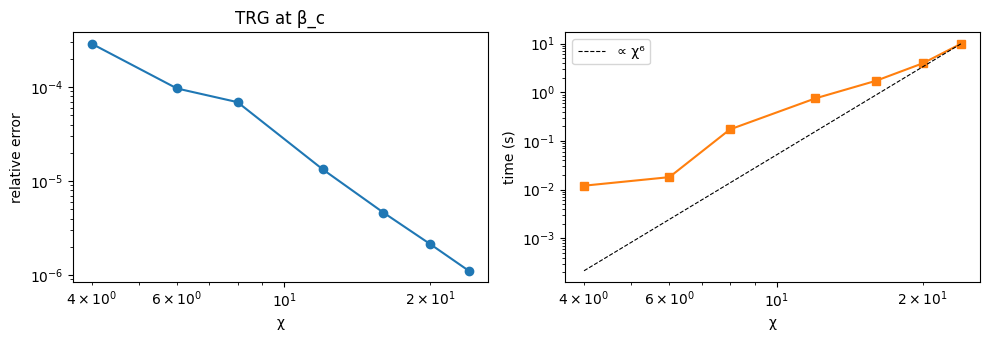

In [61]:
chis = [4, 6, 8, 12, 16, 20, 24]
errs, times = [], []
for chi in chis:
    t0 = time.time()
    f = trg_free_energy(beta_c, chi, 30)
    times.append(time.time() - t0)
    errs.append(abs(f - f_exact(beta_c)) / abs(f_exact(beta_c)))
    print(f"χ = {chi:2d}: rel. error = {errs[-1]:.2e}   ({times[-1]:.2f} s)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].loglog(chis, errs, "o-")
ax[0].set(xlabel="χ", ylabel="relative error", title="TRG at β_c")
ax[1].loglog(chis, times, "s-", color="C1")
ax[1].loglog(chis, times[-1] * (np.array(chis) / chis[-1]) ** 6, "k--", lw=0.8, label="∝ χ⁶")
ax[1].set(xlabel="χ", ylabel="time (s)")
ax[1].legend()
plt.tight_layout()
plt.show()

At criticality the error decays roughly as a **power law** in χ (straight line on log–log): there is no gap, the
entanglement of the fixed point grows without bound, and a finite χ always truncates something. Off criticality the
decay is much faster. The runtime approaches the $\chi^6$ asymptote only at large χ (numpy overheads dominate below).

#### (b) Where does it hurt?

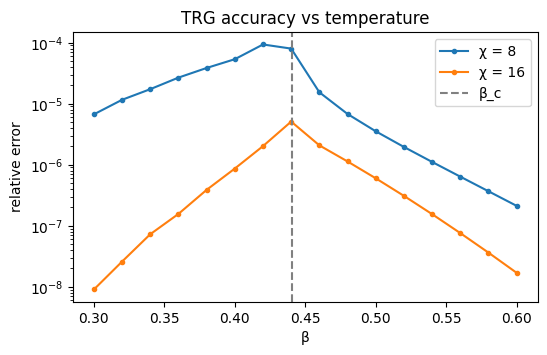

In [62]:
betas = np.linspace(0.3, 0.6, 16)
fig, ax = plt.subplots(figsize=(6, 3.5))
for chi in (8, 16):
    err = [abs(trg_free_energy(b, chi, 30) - f_exact(b)) / abs(f_exact(b)) for b in betas]
    ax.semilogy(betas, err, "o-", ms=3, label=f"χ = {chi}")
ax.axvline(beta_c, color="gray", ls="--", label="β_c")
ax.set(xlabel="β", ylabel="relative error", title="TRG accuracy vs temperature")
ax.legend()
plt.show()

The error **peaks at $\beta_c$**. There the correlation length diverges, the system is scale invariant and every RG step
has to carry entanglement from all length scales; a fixed χ cannot. Away from $\beta_c$ the tensor flows quickly
to a trivial (low-rank) fixed point and TRG is almost exact. Fixing this at criticality is what improved
schemes such as BTRG, HOTRG and LoopTNR are for (section 6).

<a id="72-switching-on-a-magnetic-field" name="72-switching-on-a-magnetic-field"></a>

### 7.2 Switching on a magnetic field

Add a field $h$ to the model:

$$Z(\beta, h) = \sum_{\{\sigma\}} \exp\Big(\beta\sum_{\langle ij\rangle}\sigma_i\sigma_j \;+\; \beta h\sum_i \sigma_i\Big).$$

The field term lives on a single site, so the bonds don't change: $W$ and $M$ stay exactly as they were. The only
change is an extra weight $e^{\beta h\sigma}$ inside the spin sum:

$$T_{ldur}(h) = \sum_{\sigma=\pm1} e^{\beta h\sigma}\, M_{\sigma l}\,M_{\sigma d}\,M_{\sigma u}\,M_{\sigma r}.$$

The field breaks the $\mathbb{Z}_2$ symmetry, so all 16 entries are now non-zero (remember the question in stop 1).

**Your tasks**
1. `ising_tensor_h(beta, h)`.
2. `free_energy_from_tensor(T, beta, chi, n_steps)`: the same as `trg_free_energy`, but starting from any tensor `T`.
   This is your stop 4 loop with `ising_tensor(beta)` replaced by `T`.

<details><summary>Hint</summary>

`np.einsum` takes the extra weight as a fifth input: `np.einsum('s,sl,sd,su,sr->ldur', w, M, M, M, M)` with
`w = np.exp(beta * h * np.array([1, -1]))`.
</details>

In [63]:
def ising_tensor_h(beta, h):
    """Ising tensor T[l, d, u, r] in a magnetic field h."""
    M = bond_factor(beta)
    w = np.exp(beta * h * np.array([1, -1]))  # e^{βhσ} for σ = +1, -1
    return np.einsum("s,sl,sd,su,sr->ldur", w, M, M, M, M)


def free_energy_from_tensor(T, beta, chi, n_steps=30):
    """Free energy per site from n_steps TRG steps, starting from the tensor T."""
    lnz = 0.0
    for k in range(n_steps + 1):
        if k > 0:
            T = trg_step(T, chi)
        n = np.einsum("abba->", T)
        T = T / n
        lnz += np.log(n) / 2**k
    return -lnz / beta

In [64]:
checkpoint_field(ising_tensor_h)
print(free_energy_from_tensor(ising_tensor_h(0.4, 0.0), 0.4, 16), trg_free_energy(0.4, 16))

✅ ln Z with a magnetic field agrees with brute force on 2x2, 3x3 and 4x4 tori.
-2.19840765079648 -2.19840765079648


<a id="73-observables-from-derivatives" name="73-observables-from-derivatives"></a>

### 7.3 Observables from derivatives

Everything thermodynamic is a derivative of $f(\beta, h)$:

| observable | definition |
|---|---|
| magnetization | $m = -\partial f/\partial h$ |
| magnetic susceptibility | $\chi_m = \partial m/\partial h = -\partial^2 f/\partial h^2$ |
| internal energy | $u = \partial(\beta f)/\partial\beta$ |
| specific heat | $C = -\beta^2\,\partial u/\partial\beta$ |

(We write $C$ for the specific heat, because $c$ is reserved for the central charge in 7.5.)

Compute them with finite differences, e.g. $m(\beta, h) \approx -\big[f(\beta, h+\delta) - f(\beta, h-\delta)\big]/2\delta$.
Finite differences amplify errors, and $f$ is only accurate to about $10^{-6}$, so don't make $\delta$ too small:
$\delta = h/10$ for $m$ and $\delta \approx 10^{-3}$ for $\chi_m$ work well. Use $\chi = 12$ for scans over many $\beta$'s;
it is about three times faster than $\chi = 16$.

**Your tasks**

**(a)** Write `magnetization(beta, h)` and plot $m$ versus $\beta \in [0.3, 0.6]$ at $h = 10^{-4}$. Compare with
`m_exact`. Why do we need a small $h > 0$ at all? What would you get at exactly $h = 0$?

**(b)** Write `susceptibility(beta)` at $h = 0$, and plot it for $\beta < \beta_c$. Since $f$ is even in $h$,
$\chi_m \approx -2\,[f(\beta, \delta) - f(\beta, 0)]/\delta^2$. What goes wrong if you use this formula for $\beta > \beta_c$?

**(c)** Compute $u$ and $C$ on a grid of $\beta$'s, compare $u$ with `u_exact`, and watch $C$ develop its peak at $\beta_c$.

<details><summary>Hint for (a) and (b)</summary>

```python
def magnetization(beta, h, chi=16):
    d = h / 10
    fp = free_energy_from_tensor(ising_tensor_h(beta, h + d), beta, chi)
    fm = free_energy_from_tensor(ising_tensor_h(beta, h - d), beta, chi)
    return -(fp - fm) / (2 * d)
```
`susceptibility` follows the same pattern with $f(\beta, \delta)$ and $f(\beta, 0)$.
</details>

<details><summary>Hint for (c)</summary>

Evaluate `bf = [b * trg_free_energy(b, 12, 30) for b in betas]` on `betas = np.linspace(0.3, 0.6, 31)`,
then `u = np.gradient(bf, betas)` and `C = -betas**2 * np.gradient(u, betas)`. Don't put a grid point
exactly at $\beta_c$ when you call `u_exact` (it is $0\cdot\infty$ there).
</details>

In [65]:
def magnetization(beta, h, chi=16):
    """m = -df/dh at field h > 0, by a central finite difference with step h/10."""
    d = h / 10
    fp = free_energy_from_tensor(ising_tensor_h(beta, h + d), beta, chi)
    fm = free_energy_from_tensor(ising_tensor_h(beta, h - d), beta, chi)
    return -(fp - fm) / (2 * d)


def susceptibility(beta, chi=16, dh=1e-3):
    """chi_m = -d²f/dh² at h = 0 (valid for beta < beta_c), using f(h) = f(-h)."""
    f0 = free_energy_from_tensor(ising_tensor_h(beta, 0.0), beta, chi)
    f1 = free_energy_from_tensor(ising_tensor_h(beta, dh), beta, chi)
    return -2 * (f1 - f0) / dh**2

#### (a) Magnetization

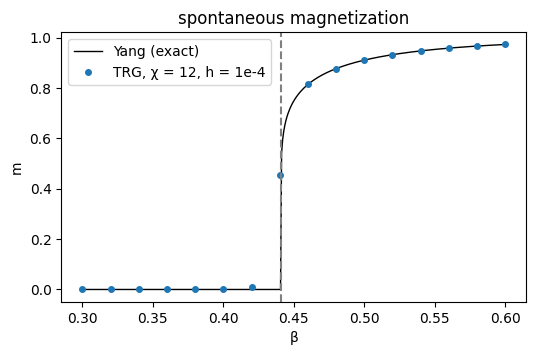

In [66]:
betas_m = np.linspace(0.3, 0.6, 16)
m_trg = [magnetization(b, 1e-4, chi=12) for b in betas_m]
fine = np.linspace(0.3, 0.6, 400)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(fine, m_exact(fine), "k-", lw=1, label="Yang (exact)")
ax.plot(betas_m, m_trg, "o", ms=4, label="TRG, χ = 12, h = 1e-4")
ax.axvline(beta_c, color="gray", ls="--")
ax.set(xlabel="β", ylabel="m", title="spontaneous magnetization")
ax.legend()
plt.show()

In the ordered phase the TRG points sit on Yang's curve. At exactly $h = 0$ the central difference gives $m = 0$ by
symmetry: the finite-size-free system is an equal mixture of the up and down states. A tiny field selects one of them,
which is spontaneous symmetry breaking in action. In the disordered phase $m \approx \chi_m h$, which is small
except right next to $\beta_c$, where $\chi_m$ is large.

#### (b) Susceptibility

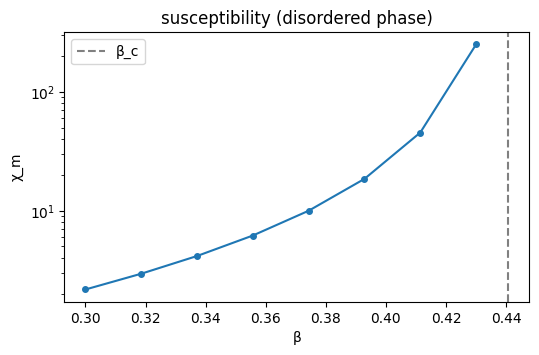

and in the ordered phase, β = 0.5: 1823.2084622544776


In [67]:
betas_chi = np.linspace(0.30, 0.43, 8)
chi_trg = [susceptibility(b, chi=12) for b in betas_chi]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(betas_chi, chi_trg, "o-", ms=4)
ax.axvline(beta_c, color="gray", ls="--", label="β_c")
ax.set(xlabel="β", ylabel="χ_m", title="susceptibility (disordered phase)")
ax.legend()
plt.show()
print("and in the ordered phase, β = 0.5:", susceptibility(0.5, chi=12))

$\chi_m$ grows by orders of magnitude towards $\beta_c$. For $\beta > \beta_c$ the formula breaks down: there
$f(\beta, h) \approx f(\beta, 0) - m_0|h|$ has a kink at $h = 0$, so the "second derivative" comes out as
$2m_0/\delta \approx 1800$ at $\beta = 0.5$, and it keeps growing as you make $\delta$ smaller. That is not a susceptibility
at all: it is the spontaneous magnetization showing up as a kink.

#### (c) Internal energy and specific heat

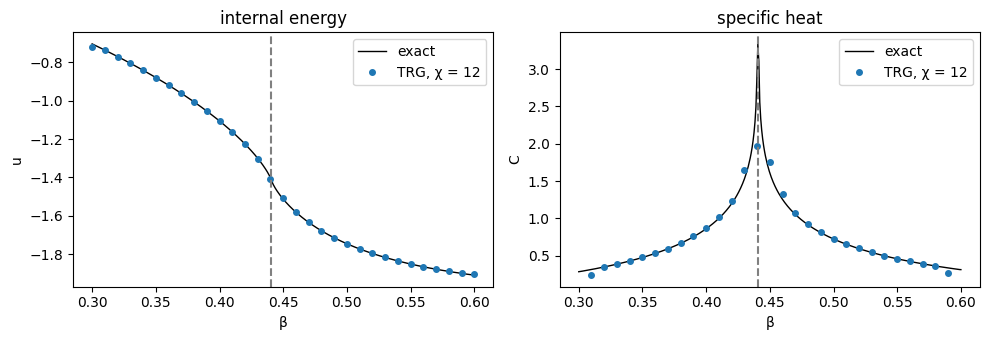

In [68]:
betas_uc = np.linspace(0.3, 0.6, 31)
bf = np.array([b * trg_free_energy(b, 12, 30) for b in betas_uc])
u_trg = np.gradient(bf, betas_uc)
C_trg = -betas_uc**2 * np.gradient(u_trg, betas_uc)

fine = np.linspace(0.3, 0.6, 400) + 1e-7  # avoid hitting β_c exactly
u_ex = u_exact(fine)
C_ex = -fine**2 * np.gradient(u_ex, fine)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(fine, u_ex, "k-", lw=1, label="exact")
ax[0].plot(betas_uc, u_trg, "o", ms=4, label="TRG, χ = 12")
ax[0].set(xlabel="β", ylabel="u", title="internal energy")
ax[1].plot(fine, C_ex, "k-", lw=1, label="exact")
ax[1].plot(betas_uc[1:-1], C_trg[1:-1], "o", ms=4, label="TRG, χ = 12")  # drop one-sided edge points
ax[1].set(xlabel="β", ylabel="C", title="specific heat")
for a in ax:
    a.axvline(beta_c, color="gray", ls="--")
    a.legend()
plt.tight_layout()
plt.show()

The TRG points follow the exact $u(\beta)$, including its infinite slope at $\beta_c$, and the specific heat shows its
peak, smeared by the finite grid and finite χ.

<a id="74-critical-exponents" name="74-critical-exponents"></a>

### 7.4 Critical exponents

Close to $\beta_c$, observables follow power laws in the reduced temperature $t = |1 - \beta/\beta_c|$, or in $h$:

| quantity | behavior | exact (2D Ising) |
|---|---|---|
| $m(h \to 0^+)$, $\beta > \beta_c$ | $\propto t^{\beta}$ | $\beta = 1/8$ |
| $m$ at $\beta_c$ | $\propto h^{1/\delta}$ | $\delta = 15$ |
| $\chi_m$, $\beta < \beta_c$ | $\propto t^{-\gamma}$ | $\gamma = 7/4$ |

(Sorry about the two $\beta$'s; that's the notation everybody uses. Conventions are annoying sometimes.)

A power law $y \propto x^{p}$ is a **straight line with slope $p$ on a log-log plot**. So: compute, plot on log-log
axes, and compare with a dashed line of the exact slope. Don't expect a perfect match everywhere. Too close to the
critical point, finite χ cuts things off; too far away, corrections to scaling take over. The exponent shows up in
the window in between.

**Your task.** Make three log-log plots, each with a reference line of the exact slope:

* **(a)** $m$ at $h = 10^{-4}$ versus $t \in [0.01, 0.16]$ above $\beta_c$. Add Yang's `m_exact` as well.
* **(b)** $m$ at $\beta = \beta_c$ versus $h \in [10^{-4}, 10^{-2}]$.
* **(c)** $\chi_m$ versus $t \in [0.01, 0.16]$ below $\beta_c$.

Where do your points run parallel to the reference line?

<details><summary>Hint</summary>

```python
ts = np.logspace(-2, np.log10(0.16), 5)
m_t = np.array([magnetization(beta_c * (1 + t), 1e-4) for t in ts])
plt.loglog(ts, m_t, "o", label="TRG")
plt.loglog(ts, m_t[2] * (ts / ts[2]) ** (1 / 8), "--", label="slope 1/8")  # through the middle point
plt.legend()
```
</details>

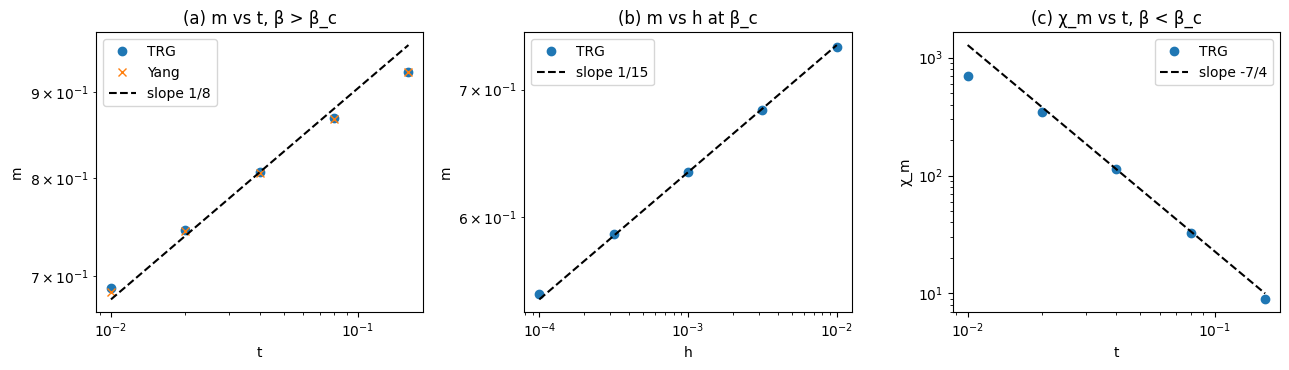

In [69]:
ts = np.logspace(-2, np.log10(0.16), 5)
hs = np.logspace(-4, -2, 5)
m_t = np.array([magnetization(beta_c * (1 + t), 1e-4) for t in ts])
m_h = np.array([magnetization(beta_c, h) for h in hs])
chi_t = np.array([susceptibility(beta_c * (1 - t)) for t in ts])


def reference(x, y, p):
    """Power law x^p through the middle point of (x, y)."""
    return y[2] * (x / x[2]) ** p


fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].loglog(ts, m_t, "o", label="TRG")
ax[0].loglog(ts, m_exact(beta_c * (1 + ts)), "x", label="Yang")
ax[0].loglog(ts, reference(ts, m_t, 1 / 8), "k--", label="slope 1/8")
ax[0].set(xlabel="t", ylabel="m", title="(a) m vs t, β > β_c")
ax[1].loglog(hs, m_h, "o", label="TRG")
ax[1].loglog(hs, reference(hs, m_h, 1 / 15), "k--", label="slope 1/15")
ax[1].set(xlabel="h", ylabel="m", title="(b) m vs h at β_c")
ax[2].loglog(ts, chi_t, "o", label="TRG")
ax[2].loglog(ts, reference(ts, chi_t, -7 / 4), "k--", label="slope -7/4")
ax[2].set(xlabel="t", ylabel="χ_m", title="(c) χ_m vs t, β < β_c")
for a in ax:
    a.legend()
plt.tight_layout()
plt.show()

* **(a)** The TRG points sit on Yang's curve, but neither runs exactly parallel to slope $1/8$ in this range:
  at $t = 0.01$–$0.16$ we are not yet in the asymptotic regime. Yang's formula is $m^8 = 1 - \sinh^{-4}(2\beta)$,
  which is $\propto t$ only up to corrections of order $t^2$.
* **(b)** From $h \approx 10^{-3}$ upwards the points follow slope $1/15$. At the smallest fields, the correlation
  length set by $h$ becomes larger than what $\chi = 16$ can describe.
* **(c)** The hardest one. Closest to $\beta_c$ the points bend below the line (finite χ: the true correlation length
  is longer than TRG can represent), far away they overshoot (corrections to scaling). Around $t \approx 0.03$–$0.06$
  they follow slope $-7/4$.

<a id="75-the-deep-end-central-charge-and-scaling-dimensions" name="75-the-deep-end-central-charge-and-scaling-dimensions"></a>

### 7.5 The deep end: central charge and scaling dimensions

At criticality the Ising model is described by a **conformal field theory** (CFT). A CFT is characterized by its
central charge $c$ and the scaling dimensions $\Delta_i$ of its operators. For the Ising CFT,
$c = 1/2$ and, from the bottom up,

$$\Delta = 0\ (\text{𝟙}),\quad \tfrac18\ (\sigma,\text{ the spin}),\quad 1\ (\varepsilon,\text{ the energy}),\quad \tfrac98,\ \tfrac98,\quad 2,\,2,\,2,\,2,\quad \tfrac{17}{8},\ \dots$$

Your TRG tensors contain all of this. Here we extract it step by step, following section 3 of the [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) paper: <https://arxiv.org/abs/2604.06922>. Reading section 3 is adviced.

#### Step 1: a tensor is a patch of spacetime

After $k$ RG steps, one normalized tensor $T_k$ stands for a square block of $2^k$ original spins. Its four legs
carry the boundary conditions on the four edges of that block. Near the critical fixed point $T_k$ barely changes from
one step to the next: it *is* the critical theory on a little square.

**Task:** write `trg_tensors(beta, chi, n_steps)`, which returns the list $[T_0, T_1, \dots, T_n]$ of tensors, each
normalized by its $1\times1$ trace (as in stop 4).

In [70]:
def trg_tensors(beta, chi, n_steps):
    """[T_0, T_1, ..., T_n]: the Ising tensor and its TRG descendants, each normalized by its 1x1 trace."""
    T = ising_tensor(beta)
    Ts = [T / np.einsum("abba->", T)]
    for _ in range(n_steps):
        T = trg_step(Ts[-1], chi)
        Ts.append(T / np.einsum("abba->", T))
    return Ts

#### Step 2: roll it into a tube

Glue the left leg of a tensor to its own right leg. You get a **tube** (a cylinder) with circumference $L = 1$ and
height $h = 1$. Read from bottom to top, that is a **transfer matrix**:

```text
          u                       M[d, u] = Σ_a T[a, d, u, a]
          |
    .-----T-----.                 the left leg a is glued to the right leg a,
    |     |     |                 d (bottom) is the input, u (top) the output
    '-----|-----'
          d
```

$M$ evolves a state on a circle by one unit of imaginary time. In a CFT that evolution operator is known exactly:
for a tube of height $h$ and circumference $L$ it is $e^{-2\pi\frac{h}{L}\left(L_0 + \bar L_0 - \frac{c}{12}\right)}$,
and the eigenvalues of $L_0 + \bar L_0$ are precisely the scaling dimensions. So the eigenvalues of $M$ are (paper,
Eq. 39)

The factor $e^{f}$ is a non-universal 'area term' (the free energy again). We can get rid of the 'area term' by taking ratios:

$$\Delta_i - \Delta_{min} \;=\; -\frac{L}{2\pi h}\,\ln\frac{\lambda_i}{\lambda_{max}},$$

Now we can only now the 'effective' scaling dimension $\Delta_i - \Delta_{min}$. Luckely, we now that for unitary CFTs, like Ising, $\Delta_{min} = 0$.

#### Step 3: wider tubes are better

Now put $L$ tensors next to each other in a ring before closing it: a tube of shape $[h, L, x] = [1, L, 0]$ in the
notation of the paper (height, circumference, horizontal shift). Two things improve with higher $L$ (paper, Sec. 3.5):

* the circle now carries $\chi^L$ states instead of $\chi$, which can help to resolve higher descendants;
* the eigenvalues decay signifant more slowly, $\lambda_i/\lambda_0 = e^{-2\pi\Delta_i/L}$, so they stay above numerical noise longer.

Taller tubes (larger $h$) do the opposite: no new states, and faster decay into noise. "Wide and short, never tall" is hence the spirit. :smile: For us $L = 1$ and $L = 2$ (a $\chi^2 \times \chi^2$ transfer matrix) are enough.

**Tasks**
1. `transfer_matrix(T, L)` for $L = 1$ and $L = 2$.
2. `scaling_dimensions(T, L, n)`: the $n$ lowest $\Delta_i$ from the $[1, L, 0]$ tube.

<details><summary>Hint 1: the L = 2 ring</summary>

Two tensors, the right leg of the first glued to the left leg of the second, and the right leg of the second
glued back to the left leg of the first. The two down legs together form the input, the two up legs the output:
```python
D = T.shape[1]
M = np.einsum('adub,beva->deuv', T, T).reshape(D * D, D * D)
```
</details>

<details><summary>Hint 2: eigenvalues</summary>

`np.linalg.eigvals(M)`, then sort by absolute value, largest first. Use `np.abs`: tiny imaginary parts are numerical
noise. Then `Delta = -(L / (2 * np.pi)) * np.log(lam / lam[0])`.
</details>

In [71]:
def transfer_matrix(T, L=1):
    """Transfer matrix of the [1, L, 0] tube: L copies of T in a ring. Rows = down legs, columns = up legs."""
    if L == 1:
        return np.einsum("adua->du", T)
    if L == 2:
        D = T.shape[1]
        return np.einsum("adub,beva->deuv", T, T).reshape(D * D, D * D)
    raise NotImplementedError("L = 1 or 2")


def leading_eigenvalues(M):
    lam = np.abs(np.linalg.eigvals(M))
    return np.sort(lam)[::-1]


def scaling_dimensions(T, L=1, n=10):
    """The n lowest scaling dimensions from the [1, L, 0] tube."""
    lam = leading_eigenvalues(transfer_matrix(T, L))[:n]
    with np.errstate(divide="ignore"):
        return -(L / (2 * np.pi)) * np.log(lam / lam[0])

#### Step 4: the central charge

In a single tube, $c$ hides inside the unknown area term: $\lambda_0 \approx e^{f}e^{2\pi c/12}$. The trick (paper,
Sec. 3.3) is to compare two different shapes. For a tube of shape $[m, n, 0]$ the leading eigenvalue is
$\lambda'_0 \approx e^{fmn}\,e^{-2\pi\frac{m}{n}\left(\Delta_0 - \frac{c}{12}\right)}$, so together with $\lambda_0$ from the $[1, 1, 0]$ tube

$$c - 12\Delta_0 \;\approx\; \frac{12}{2\pi m\left(\frac1n - n\right)}\,\ln\frac{\lambda'_0}{\lambda_0^{\,mn}} .$$

For our $[1, 2, 0]$ ring ($m = 1$, $n = 2$, and $\Delta_0 = 0$) this becomes

$$c \;\approx\; -\frac{4}{\pi}\,\ln\frac{\lambda'_0}{\lambda_0^{2}} .$$

Both eigenvalues must come from the **same** tensor with the **same** normalization, otherwise the area terms don't cancel.

**Task:** `central_charge(T)`. Then run the checkpoint: it takes your tensor after 8 TRG steps at $\beta_c$ with $\chi = 16$.

In [72]:
def central_charge(T):
    """c from the leading eigenvalues of the [1, 1, 0] and [1, 2, 0] tubes."""
    lam1 = leading_eigenvalues(transfer_matrix(T, 1))[0]
    lam2 = leading_eigenvalues(transfer_matrix(T, 2))[0]
    return -(4 / np.pi) * np.log(lam2 / lam1**2)

In [73]:
checkpoint_cft(trg_tensors, scaling_dimensions, central_charge)

   step 8, χ = 16:  c = 0.4986,  Δ = [-0.      0.1249  1.0038  1.1272  1.1309  2.0033]
✅ Δ_σ ≈ 1/8 and Δ_ε ≈ 1.
✅ c ≈ 1/2. You just identified the Ising CFT from a 16x16x16x16 array of numbers.


True

#### Step 5: watch the RG flow

Plot $c$ and the lowest ~9 nonzero $\Delta_i$ (from the $L = 2$ tube) against the RG step $k = 1, \dots, 24$ at $\beta_c$ with
$\chi = 16$, with dashed lines at the exact values (`ISING_CFT`).

* After how many steps do you reach the fixed point? How long do you stay there? What happens afterwards?
* Try $\chi = 24$. What changes?

<details><summary>Hint</summary>

```python
Ts = trg_tensors(beta_c, 16, 24)
cs = [central_charge(T) for T in Ts[1:]]
Ds = np.array([scaling_dimensions(T, 2, 10) for T in Ts[1:]])
# plot cs, and Ds[:, i] for i = 1..9, against k = 1..24
```
</details>

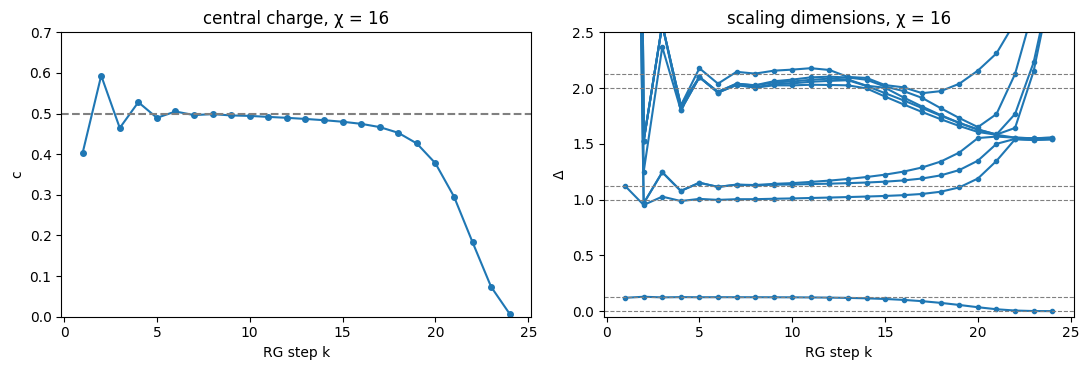

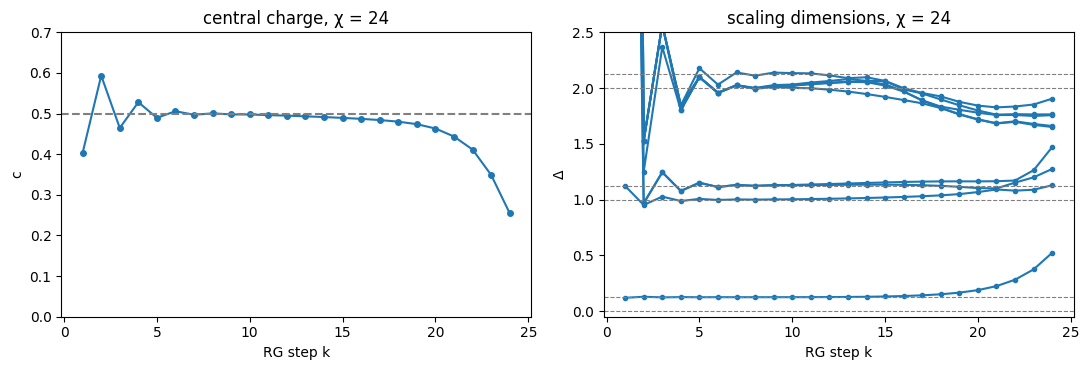

step 8, χ = 24:  c = 0.5006
Δ = [-0.     0.125  1.     1.123  1.124  1.993  1.996  1.997  2.001  2.111]
exact: [0.    0.125 1.    1.125 1.125 2.    2.    2.    2.    2.125]


In [74]:
for chi in (16, 24):
    Ts = trg_tensors(beta_c, chi, 24)
    ks = np.arange(1, 25)
    cs = [central_charge(T) for T in Ts[1:]]
    Ds = np.array([scaling_dimensions(T, 2, 10) for T in Ts[1:]])

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(ks, cs, "o-", ms=4)
    ax[0].axhline(0.5, color="gray", ls="--")
    ax[0].set(xlabel="RG step k", ylabel="c", ylim=(0, 0.7), title=f"central charge, χ = {chi}")
    for i in range(1, 10):
        ax[1].plot(ks, Ds[:, i], "o-", ms=3, color="C0")
    for d in sorted(set(ISING_CFT)):
        ax[1].axhline(d, color="gray", ls="--", lw=0.8)
    ax[1].set(xlabel="RG step k", ylabel="Δ", ylim=(-0.05, 2.5), title=f"scaling dimensions, χ = {chi}")
    plt.tight_layout()
    plt.show()

Ts = trg_tensors(beta_c, 24, 8)
print("step 8, χ = 24:  c =", round(central_charge(Ts[8]), 4))
print("Δ =", np.round(scaling_dimensions(Ts[8], 2, 10), 3))
print("exact:", np.round(ISING_CFT, 3))

* The first few steps oscillate: lattice artifacts are still dying out.
* Around steps 6–12 everything sits on the exact values: $c \approx 0.50$ and $\Delta \approx 0, 0.125, 1.00, 1.125, 1.125$, followed by
  **four** levels near 2 ($T$, $\bar T$, $\partial\varepsilon$, $\bar\partial\varepsilon$) and $17/8$. The $L = 2$ tube is what resolves those.
* After ~15 steps the data drift away. TRG cannot remove short-range ("corner double line") entanglement, which
  piles up and eats the bond dimension, so the flow slides off the critical fixed point. A larger χ delays this
  but does not cure it. LoopTNR, which removes that entanglement, is the cure (section 6); its spectrum stays flat for 20+ steps.

#### Step 6: away from criticality

Repeat at $\beta = 0.95\,\beta_c$ and $\beta = 1.05\,\beta_c$, and print $c$ and the lowest few $\Delta_i$ (with $L = 1$) after ~20 steps.
What happened to the CFT? How many eigenvalues of the transfer matrix are (nearly) degenerate in each phase,
and what does that number mean?

In [75]:
for b in (0.95 * beta_c, 1.05 * beta_c):
    T = trg_tensors(b, 16, 20)[-1]
    lam = leading_eigenvalues(transfer_matrix(T, 1))[:4]
    print(f"β/β_c = {b / beta_c:.2f}:  c = {central_charge(T):+.3f},  λ_i/λ_0 = {np.round(lam / lam[0], 4)}")

β/β_c = 0.95:  c = -0.000,  λ_i/λ_0 = [1. 0. 0. 0.]
β/β_c = 1.05:  c = -0.000,  λ_i/λ_0 = [1. 1. 0. 0.]


Off criticality the flow ends in a **trivial** fixed point: the correlation length is finite, so after enough steps it is
smaller than one tensor.

* **Disordered** ($\beta < \beta_c$): one eigenvalue survives, all others go to zero. That is a unique ground state with a gap.
* **Ordered** ($\beta > \beta_c$): **two** equal eigenvalues, one for each ordered state ("all up" and "all down").
  The number of degenerate leading eigenvalues counts the ground states. [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) calls this `ground_state_degeneracy`.

And $c \to 0$ in both phases: a trivial fixed point has no long-range fluctuations left, so there is no Casimir
energy for a central charge to show up in.

#### In TNRKit
In [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl), everything in 7.5 is one call: `CFTData(scheme; shape = [1, 1, 0])`. The default shape is $[\sqrt2, 2\sqrt2, 0]$, and
$[1, 4, 1]$ adds a horizontal shift that also gives the **conformal spins** $s_i$ from the phases of $\lambda_i$
(paper, Secs. 3.4–3.7, including the "jigsaw trick" for building wide tubes cheaply). Combined with LoopTNR, the
spectrum stays on the plateau instead of drifting away (see section 6).